# 19 — Regional Spatial + Wind Mechanism Experiment
## T2 support-only locked domain, 0.25° grid

### Purpose

Notebook 18 V2 established that local temporal information is strong overall, while
**Emerging-3** cases remain substantially harder. Same-cell weather did not improve
the legacy LR ranking, so this notebook tests a more specific mechanism:

> Does **same-day hotspot activity in neighboring cells**, especially activity aligned
> with the direction of wind transport, add next-day predictive information beyond
> the local baseline?

This notebook is intentionally **not a GNN notebook yet**. It tests whether the
spatial signal we want a graph model to exploit is empirically present first.

### Primary comparison

All models predict FIRMS-detected hotspot activity at `t+1`.

```text
LR13  local current fire + fire history
  ↓
LR23  + same-cell weather
  ↓
LR27  + generic neighbor activity
  ↓
LR31  + wind-aligned neighbor exposure
```

The exact model names use feature counts only as shorthand; interpretation is based on
the feature groups, not on the number itself.

### Timing

The main regime is end-of-day `t`:

- local fire: day `t`
- neighbor fire: day `t`
- ERA5 weather / wind: day `t`
- target: FIRMS-detected hotspot on `t+1`

No feature uses `t+1`.

### Spatial scale

The **primary radius is pre-specified at 75 km**, appropriate for a 0.25° grid where
adjacent cell centers are roughly a few tens of kilometers apart.

50 km and 100 km are reported only as **exploratory sensitivity checks**.

### Evaluation

- Train: May–July 2026
- Validation: August 2026
- September: **SEALED**
- Primary metric: PR-AUC
- Key subgroup: Emerging-3 eligible rows
- Persistent context is reported separately

Wind-aware features are **associative transport-aware predictors**, not proof that one
detected hotspot caused another.

In [2]:
# 1. Imports

from pathlib import Path
import sys
import json
import importlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)

RANDOM_STATE = 42
PRIMARY_RADIUS_KM = 75.0
SENSITIVITY_RADII_KM = [50.0, 75.0, 100.0]
RUN_TEST = False

In [3]:
# 2. Resolve project root and Notebook 17 V2 metadata

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional 0.25° dataset. "
        "Run Notebook 17 V2 first or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NODE_PATH = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "regional_025"
    / "regional_grid_nodes_025.csv"
)

NB17_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
)

LOCK_PATH = (
    NB17_EXPORT_DIR
    / "regional_domain_lock_train_only.json"
)

METHODOLOGY_PATH = (
    NB17_EXPORT_DIR
    / "regional_025_methodology_metadata.json"
)

for required_path in [
    DATA_PATH,
    NODE_PATH,
    LOCK_PATH,
    METHODOLOGY_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Notebook 17 V2 artifact is missing: {required_path}"
        )

lock_metadata = json.loads(
    LOCK_PATH.read_text(encoding="utf-8")
)

methodology_metadata = json.loads(
    METHODOLOGY_PATH.read_text(encoding="utf-8")
)

LOCKED_REGION_ID = str(
    lock_metadata["candidate_id"]
)

EXPECTED_NODES = int(
    methodology_metadata["weather"]["requested_grid_centers"]
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_spatial_wind"
    / LOCKED_REGION_ID.lower()
)

FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_DIR = RESULTS_DIR / "exports"

for p in [
    RESULTS_DIR,
    FIGURES_DIR,
    EXPORT_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT  :", PROJECT_ROOT)
print("Locked region :", LOCKED_REGION_ID)
print("Expected nodes:", EXPECTED_NODES)
print("RESULTS_DIR   :", RESULTS_DIR)

PROJECT_ROOT  : c:\Users\Asus\Documents\skripsi-karhut
Locked region : T2
Expected nodes: 133
RESULTS_DIR   : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2


In [4]:
# 3. Import reusable modules from src/karhut

SRC_ROOT = PROJECT_ROOT / "src"

if not SRC_ROOT.exists():
    raise FileNotFoundError(
        f"{SRC_ROOT} does not exist. Copy the supplied src/karhut modules "
        "into the project root before running Notebook 19."
    )

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

import karhut.spatial as spatial
import karhut.wind as wind
import karhut.evaluation as evaluation

# Helpful when editing modules while a notebook kernel is still alive.
importlib.reload(spatial)
importlib.reload(wind)
importlib.reload(evaluation)

print("Reusable modules imported from:", SRC_ROOT)

Reusable modules imported from: c:\Users\Asus\Documents\skripsi-karhut\src


In [5]:
# 4. Load current support-only regional dataset

regional = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

nodes = pd.read_csv(
    NODE_PATH,
)

regional["cell_id"] = regional["cell_id"].astype(str)
nodes["cell_id"] = nodes["cell_id"].astype(str)

N_NODES = regional["cell_id"].nunique()

assert N_NODES == EXPECTED_NODES
assert nodes["cell_id"].nunique() == EXPECTED_NODES
assert regional.duplicated(["date", "cell_id"]).sum() == 0

assert lock_metadata.get("selection_uses_emerging3") is False
assert lock_metadata.get("selection_uses_august") is False
assert lock_metadata.get("selection_uses_september") is False

print("Region :", LOCKED_REGION_ID)
print("Nodes  :", N_NODES)
print("Rows   :", len(regional))
print(
    "Dates  :",
    regional["date"].min().date(),
    "→",
    regional["date"].max().date(),
)
print("✅ Support-only region provenance passed.")

Region : T2
Nodes  : 133
Rows   : 16625
Dates  : 2026-05-08 → 2026-09-09
✅ Support-only region provenance passed.


In [6]:
# 5. Feature definitions

CURRENT_DAY_FIRE = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

FIRE_HISTORY = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

WEATHER = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

GENERIC_SPATIAL = [
    "nbr_active_fraction_t",
    "nbr_active_any_t",
    "nbr_distw_fire_count_log1p_t",
    "nbr_distw_frp_log1p_t",
]

WIND_SPATIAL = [
    "upwind_active_exposure_t",
    "upwind_fire_count_exposure_log1p_t",
    "upwind_frp_exposure_log1p_t",
    "upwind_active_windspeed_exposure_t",
]

TARGET = "target_fire_active_t1"

LR13_LOCAL = CURRENT_DAY_FIRE + FIRE_HISTORY
LR23_LOCAL_WEATHER = LR13_LOCAL + WEATHER
LR27_GENERIC = LR23_LOCAL_WEATHER + GENERIC_SPATIAL
LR31_WIND = LR27_GENERIC + WIND_SPATIAL

required = set(
    LR23_LOCAL_WEATHER
    + [
        TARGET,
        "date",
        "cell_id",
        "grid_lat",
        "grid_lon",
        "active_days_prev3_incl_t",
        "event_type_3d",
    ]
)

missing = sorted(required - set(regional.columns))

if missing:
    raise ValueError(
        f"Regional dataset is missing required columns: {missing}"
    )

print("LR13 local fire/history       :", len(LR13_LOCAL))
print("LR23 + same-cell weather      :", len(LR23_LOCAL_WEATHER))
print("LR27 + generic spatial        :", len(LR27_GENERIC))
print("LR31 + wind-aware spatial     :", len(LR31_WIND))

LR13 local fire/history       : 13
LR23 + same-cell weather      : 23
LR27 + generic spatial        : 27
LR31 + wind-aware spatial     : 31


# PART A — Build the primary 75 km spatial graph

The graph here is only a deterministic neighborhood structure used for feature
engineering. No GCN/GAT is trained yet.

An edge `A → B` means activity at source cell A may contribute to features for target
cell B.

In [7]:
# 6. Build 75 km directed radius graph

node_table = (
    regional[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    ]
    .drop_duplicates("cell_id")
    .sort_values("cell_id")
    .reset_index(drop=True)
)

edges_75 = spatial.build_radius_edges(
    node_table,
    PRIMARY_RADIUS_KM,
)

degree_75 = spatial.graph_degree_summary(
    edges_75
)

print("Nodes              :", len(node_table))
print("Directed edges     :", len(edges_75))
print(
    "Neighbor degree    :",
    "min =", int(degree_75["neighbor_degree"].min()),
    "| median =", round(float(degree_75["neighbor_degree"].median()), 2),
    "| mean =", round(float(degree_75["neighbor_degree"].mean()), 2),
    "| max =", int(degree_75["neighbor_degree"].max()),
)

if len(degree_75) != len(node_table):
    isolated = sorted(
        set(node_table["cell_id"])
        - set(degree_75["target_cell_id"])
    )
    print("Structurally isolated nodes:", len(isolated))
else:
    print("Structurally isolated nodes: 0")

display(edges_75.head(10))

Nodes              : 133
Directed edges     : 2152
Neighbor degree    : min = 6 | median = 17.0 | mean = 16.18 | max = 20
Structurally isolated nodes: 0


,source_cell_id,target_cell_id,distance_km,bearing_source_to_target_deg,distance_weight,radius_km
0,regional025_10_23,regional025_10_22,27.783886,269.995910,0.690422,75.0
1,regional025_11_22,regional025_10_22,27.798770,180.000000,0.690285,75.0
2,regional025_9_22,regional025_10_22,27.798770,0.000000,0.690285,75.0
3,regional025_9_23,regional025_10_22,39.301409,315.013026,0.592136,75.0
4,regional025_11_23,regional025_10_22,39.304215,224.982886,0.592114,75.0
5,regional025_10_24,regional025_10_22,55.567772,269.991820,0.476683,75.0
6,regional025_12_22,regional025_10_22,55.597540,180.000000,0.476494,75.0
7,regional025_8_22,regional025_10_22,55.597540,0.000000,0.476494,75.0
8,regional025_9_24,regional025_10_22,62.129609,296.570131,0.436750,75.0
9,regional025_11_24,regional025_10_22,62.136707,243.416784,0.436708,75.0


In [8]:
# 7. Development period only: May–August
# September is not used for feature analysis or model evaluation here.

DEV_END = pd.Timestamp("2026-08-31")

dev = (
    regional[
        regional["date"] <= DEV_END
    ]
    .copy()
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

assert dev["date"].max() == DEV_END
assert not (dev["date"] >= pd.Timestamp("2026-09-01")).any()

print(
    "Development rows:",
    len(dev),
    "| dates:",
    dev["date"].min().date(),
    "→",
    dev["date"].max().date(),
)
print("September: SEALED")

Development rows: 15428 | dates: 2026-05-08 → 2026-08-31
September: SEALED


In [9]:
# 8. Generic neighbor features

dev_generic = spatial.add_neighbor_fire_features(
    dev,
    edges_75,
)

print(
    "Generic spatial missing values:",
    int(
        dev_generic[
            GENERIC_SPATIAL
        ].isna().sum().sum()
    ),
)

display(
    dev_generic[
        [
            "date",
            "cell_id",
            "fire_active",
            *GENERIC_SPATIAL,
        ]
    ].head()
)

Generic spatial missing values: 0


,date,cell_id,fire_active,nbr_active_fraction_t,nbr_active_any_t,nbr_distw_fire_count_log1p_t,nbr_distw_frp_log1p_t
0,2026-05-08,regional025_10_22,0,0.0,0.0,0.0,0.0
1,2026-05-08,regional025_10_23,0,0.0,0.0,0.0,0.0
2,2026-05-08,regional025_10_24,0,0.0,0.0,0.0,0.0
3,2026-05-08,regional025_10_25,0,0.0,0.0,0.0,0.0
4,2026-05-08,regional025_10_26,0,0.0,0.0,0.0,0.0


In [10]:
# 9. Wind-aware neighbor features

dev_spatial = wind.add_upwind_fire_features(
    dev_generic,
    edges_75,
)

missing_spatial = (
    dev_spatial[
        GENERIC_SPATIAL
        + WIND_SPATIAL
    ]
    .isna()
    .sum()
)

display(
    missing_spatial.to_frame("missing")
)

if missing_spatial.sum() > 0:
    raise ValueError(
        "Spatial/wind feature construction produced missing values."
    )

print("✅ 75 km generic + wind-aware features created.")

,missing
nbr_active_fraction_t,0
nbr_active_any_t,0
nbr_distw_fire_count_log1p_t,0
nbr_distw_frp_log1p_t,0
upwind_active_exposure_t,0
upwind_fire_count_exposure_log1p_t,0
upwind_frp_exposure_log1p_t,0
upwind_active_windspeed_exposure_t,0


✅ 75 km generic + wind-aware features created.


## Wind interpretation

The wind features use **source-cell daily wind vectors**. If the source wind vector
points toward the target cell, the source's fire activity receives a positive
alignment weight.

This should be described as **wind-aligned neighboring hotspot exposure**, not as
observed fire spread or causal propagation.

In [11]:
# 10. Timing and leakage sanity checks

# Every feature in Notebook 19 is day t or earlier.
# The label is already precomputed by Notebook 17 as day t+1.
#
# We additionally verify that the feature table still contains one row per
# date-cell and no target-derived columns were introduced by the modules.

assert dev_spatial.duplicated(["date", "cell_id"]).sum() == 0

for features in [
    LR13_LOCAL,
    LR23_LOCAL_WEATHER,
    LR27_GENERIC,
    LR31_WIND,
]:
    assert dev_spatial[features].isna().sum().sum() == 0

print("Feature timing contract:")
print("  local current fire : day t")
print("  neighbor fire      : day t")
print("  weather / wind     : day t")
print("  target             : day t+1")
print("✅ Feature integrity checks passed.")

Feature timing contract:
  local current fire : day t
  neighbor fire      : day t
  weather / wind     : day t
  target             : day t+1
✅ Feature integrity checks passed.


# PART B — Train / August validation comparison

The comparison is cumulative so each delta answers a specific question:

```text
LR13 → LR23 : does same-cell weather add information?
LR23 → LR27 : does generic neighbor activity add information?
LR27 → LR31 : does wind alignment add information beyond generic neighbors?
```

In [12]:
# 11. Time split

VALIDATION_START = pd.Timestamp("2026-08-01")
VALIDATION_END = pd.Timestamp("2026-08-31")

train = (
    dev_spatial[
        dev_spatial["date"] < VALIDATION_START
    ]
    .copy()
)

val = (
    dev_spatial[
        dev_spatial["date"].between(
            VALIDATION_START,
            VALIDATION_END,
            inclusive="both",
        )
    ]
    .copy()
)

print(
    pd.DataFrame([
        {
            "Split": "Train",
            "Start": train["date"].min(),
            "End": train["date"].max(),
            "Rows": len(train),
            "Nodes": train["cell_id"].nunique(),
            "Positives": int(train[TARGET].sum()),
            "Positive Rate": float(train[TARGET].mean()),
        },
        {
            "Split": "Validation",
            "Start": val["date"].min(),
            "End": val["date"].max(),
            "Rows": len(val),
            "Nodes": val["cell_id"].nunique(),
            "Positives": int(val[TARGET].sum()),
            "Positive Rate": float(val[TARGET].mean()),
        },
        {
            "Split": "Test",
            "Start": pd.Timestamp("2026-09-01"),
            "End": pd.NaT,
            "Rows": "SEALED",
            "Nodes": "SEALED",
            "Positives": "SEALED",
            "Positive Rate": "SEALED",
        },
    ])
)

if RUN_TEST:
    raise RuntimeError(
        "RUN_TEST must remain False in Notebook 19."
    )

        Split      Start        End    Rows   Nodes Positives Positive Rate
0       Train 2026-05-08 2026-07-31   11305     133       833      0.073684
1  Validation 2026-08-01 2026-08-31    4123     133      2169      0.526073
2        Test 2026-09-01        NaT  SEALED  SEALED    SEALED        SEALED


In [13]:
# 12. Fit cumulative Logistic Regression mechanism models

feature_sets = {
    "LR13 — Local current fire + history": LR13_LOCAL,
    "LR23 — LR13 + same-cell weather": LR23_LOCAL_WEATHER,
    "LR27 — LR23 + generic spatial": LR27_GENERIC,
    "LR31 — LR27 + wind-aware spatial": LR31_WIND,
}

models = {}
val_scores = {}
overall_rows = []

y_val = val[TARGET].astype(int).to_numpy()
val_prevalence = float(y_val.mean())

for name, features in feature_sets.items():
    model = evaluation.fit_logistic(
        train,
        features,
        TARGET,
        random_state=RANDOM_STATE,
    )

    score = model.predict_proba(
        val[features]
    )[:, 1]

    models[name] = model
    val_scores[name] = score

    overall_rows.append({
        "Model": name,
        "Features": len(features),
        **evaluation.binary_metrics(
            y_val,
            score,
            threshold=0.5,
        ),
    })

overall_results = (
    pd.DataFrame(overall_rows)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

print("August prevalence:", round(val_prevalence, 6))
display(overall_results)

August prevalence: 0.526073


,Model,Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR27 — LR23 + generic spatial,27,0.877588,0.853682,0.555094,0.984786,0.709988,0.576764,0.300253,0.5
1,LR13 — Local current fire + history,13,0.877455,0.858476,0.707635,0.875980,0.782859,0.744361,0.196675,0.5
2,LR23 — LR13 + same-cell weather,23,0.876138,0.849698,0.574287,0.965883,0.720303,0.605384,0.261741,0.5
3,LR31 — LR27 + wind-aware spatial,31,0.874095,0.848382,0.556949,0.982941,0.711022,0.579675,0.297443,0.5


In [14]:
# 13. Mechanism deltas

pr = (
    overall_results
    .set_index("Model")["PR-AUC"]
    .to_dict()
)

mechanism_deltas = pd.DataFrame([
    {
        "Question": "Same-cell weather beyond local fire/history",
        "From": "LR13",
        "To": "LR23",
        "Delta PR-AUC": (
            pr["LR23 — LR13 + same-cell weather"]
            - pr["LR13 — Local current fire + history"]
        ),
    },
    {
        "Question": "Generic spatial beyond local + weather",
        "From": "LR23",
        "To": "LR27",
        "Delta PR-AUC": (
            pr["LR27 — LR23 + generic spatial"]
            - pr["LR23 — LR13 + same-cell weather"]
        ),
    },
    {
        "Question": "Wind alignment beyond generic spatial",
        "From": "LR27",
        "To": "LR31",
        "Delta PR-AUC": (
            pr["LR31 — LR27 + wind-aware spatial"]
            - pr["LR27 — LR23 + generic spatial"]
        ),
    },
])

display(mechanism_deltas)

,Question,From,To,Delta PR-AUC
0,Same-cell weather beyond local fire/history,LR13,LR23,-0.001317
1,Generic spatial beyond local + weather,LR23,LR27,0.001450
2,Wind alignment beyond generic spatial,LR27,LR31,-0.003493


# PART C — Emerging-3 versus persistent context

For Emerging-3 evaluation, the eligible population contains **all rows with no local
fire detected over `t-2:t`**. Within that population:

- positive = target `t+1` is active;
- negative = target `t+1` remains not detected.

This keeps PR-AUC meaningful.

In [15]:
# 14. Emerging/Persistent subgroup metrics

eligible_emerging = (
    val["active_days_prev3_incl_t"]
    .eq(0)
    .to_numpy()
)

eligible_persistent = (
    val["active_days_prev3_incl_t"]
    .gt(0)
    .to_numpy()
)

subgroup_rows = []

for model_name, score in val_scores.items():

    subgroup_rows.append({
        "Model": model_name,
        "Context": "Emerging-3 eligible",
        **evaluation.eligible_subset_metrics(
            val,
            score,
            eligible_emerging,
            TARGET,
        ),
    })

    subgroup_rows.append({
        "Model": model_name,
        "Context": "Persistent-context",
        **evaluation.eligible_subset_metrics(
            val,
            score,
            eligible_persistent,
            TARGET,
        ),
    })

subgroup_results = pd.DataFrame(
    subgroup_rows
)

display(subgroup_results)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
0,LR13 — Local current fire + history,Emerging-3 eligible,1241,224,0.180500,0.277072,0.147321,0.370787
1,LR13 — Local current fire + history,Persistent-context,2882,1945,0.674879,0.909001,0.959897,0.719183
2,LR23 — LR13 + same-cell weather,Emerging-3 eligible,1241,224,0.180500,0.229095,0.750000,0.201439
3,LR23 — LR13 + same-cell weather,Persistent-context,2882,1945,0.674879,0.909572,0.990746,0.684790
4,LR27 — LR23 + generic spatial,Emerging-3 eligible,1241,224,0.180500,0.259863,0.892857,0.198020
5,LR27 — LR23 + generic spatial,Persistent-context,2882,1945,0.674879,0.909679,0.995373,0.682171
6,LR31 — LR27 + wind-aware spatial,Emerging-3 eligible,1241,224,0.180500,0.246402,0.888393,0.201417
7,LR31 — LR27 + wind-aware spatial,Persistent-context,2882,1945,0.674879,0.907157,0.993830,0.680634


In [16]:
# 15. Emerging-3 mechanism deltas

emerging_lookup = (
    subgroup_results[
        subgroup_results["Context"].eq(
            "Emerging-3 eligible"
        )
    ]
    .set_index("Model")["PR-AUC"]
    .to_dict()
)

emerging_deltas = pd.DataFrame([
    {
        "Question": "Same-cell weather beyond local fire/history",
        "Delta Emerging PR-AUC": (
            emerging_lookup["LR23 — LR13 + same-cell weather"]
            - emerging_lookup["LR13 — Local current fire + history"]
        ),
    },
    {
        "Question": "Generic spatial beyond local + weather",
        "Delta Emerging PR-AUC": (
            emerging_lookup["LR27 — LR23 + generic spatial"]
            - emerging_lookup["LR23 — LR13 + same-cell weather"]
        ),
    },
    {
        "Question": "Wind alignment beyond generic spatial",
        "Delta Emerging PR-AUC": (
            emerging_lookup["LR31 — LR27 + wind-aware spatial"]
            - emerging_lookup["LR27 — LR23 + generic spatial"]
        ),
    },
])

display(emerging_deltas)

,Question,Delta Emerging PR-AUC
0,Same-cell weather beyond local fire/history,-0.047977
1,Generic spatial beyond local + weather,0.030769
2,Wind alignment beyond generic spatial,-0.013462


In [17]:
# 16. Positive-event recall diagnostic at threshold 0.5
# Secondary only; PR-AUC remains the primary subgroup comparison.

event_rows = []

for model_name, score in val_scores.items():
    pred = (
        np.asarray(score) >= 0.5
    ).astype(int)

    for event_type in [
        "Emerging",
        "Persistent",
    ]:
        mask = (
            val["event_type_3d"]
            .eq(event_type)
            .to_numpy()
        )

        event_rows.append({
            "Model": model_name,
            "Event type": event_type,
            "N positives": int(mask.sum()),
            "Recall@0.5": (
                float(pred[mask].mean())
                if mask.sum() > 0
                else np.nan
            ),
        })

event_recall = pd.DataFrame(event_rows)

display(event_recall)

,Model,Event type,N positives,Recall@0.5
0,LR13 — Local current fire + history,Emerging,224,0.147321
1,LR13 — Local current fire + history,Persistent,1945,0.959897
2,LR23 — LR13 + same-cell weather,Emerging,224,0.750000
3,LR23 — LR13 + same-cell weather,Persistent,1945,0.990746
4,LR27 — LR23 + generic spatial,Emerging,224,0.892857
5,LR27 — LR23 + generic spatial,Persistent,1945,0.995373
6,LR31 — LR27 + wind-aware spatial,Emerging,224,0.888393
7,LR31 — LR27 + wind-aware spatial,Persistent,1945,0.993830


# PART D — Radius sensitivity

**75 km is the primary pre-specified radius.**

50 km and 100 km are exploratory checks only. Do not select a final radius solely
because it gives the numerically highest August score; look for a stable pattern.

In [18]:
# 17. Radius sensitivity: generic + wind-aware model

radius_rows = []

for radius_km in SENSITIVITY_RADII_KM:

    edges = spatial.build_radius_edges(
        node_table,
        radius_km,
    )

    temp = spatial.add_neighbor_fire_features(
        dev,
        edges,
    )

    temp = wind.add_upwind_fire_features(
        temp,
        edges,
    )

    temp_train = temp[
        temp["date"] < VALIDATION_START
    ].copy()

    temp_val = temp[
        temp["date"].between(
            VALIDATION_START,
            VALIDATION_END,
            inclusive="both",
        )
    ].copy()

    model = evaluation.fit_logistic(
        temp_train,
        LR31_WIND,
        TARGET,
        random_state=RANDOM_STATE,
    )

    score = model.predict_proba(
        temp_val[LR31_WIND]
    )[:, 1]

    overall_pr = evaluation.binary_metrics(
        temp_val[TARGET],
        score,
    )["PR-AUC"]

    emerg_mask = (
        temp_val["active_days_prev3_incl_t"]
        .eq(0)
        .to_numpy()
    )

    emerg = evaluation.eligible_subset_metrics(
        temp_val,
        score,
        emerg_mask,
        TARGET,
    )

    degree = spatial.graph_degree_summary(
        edges
    )

    radius_rows.append({
        "Radius km": radius_km,
        "Directed edges": len(edges),
        "Mean degree": float(
            degree["neighbor_degree"].mean()
        ),
        "Overall PR-AUC": overall_pr,
        "Emerging-3 PR-AUC": emerg["PR-AUC"],
        "Emerging rows": emerg["Rows"],
        "Emerging positives": emerg["Positives"],
        "Primary radius": radius_km == PRIMARY_RADIUS_KM,
    })

radius_sensitivity = pd.DataFrame(
    radius_rows
)

display(radius_sensitivity)

,Radius km,Directed edges,Mean degree,Overall PR-AUC,Emerging-3 PR-AUC,Emerging rows,Emerging positives,Primary radius
0,50.0,922,6.932331,0.874687,0.239467,1241,224,False
1,75.0,2152,16.180451,0.874095,0.246402,1241,224,True
2,100.0,3612,27.157895,0.873747,0.252993,1241,224,False


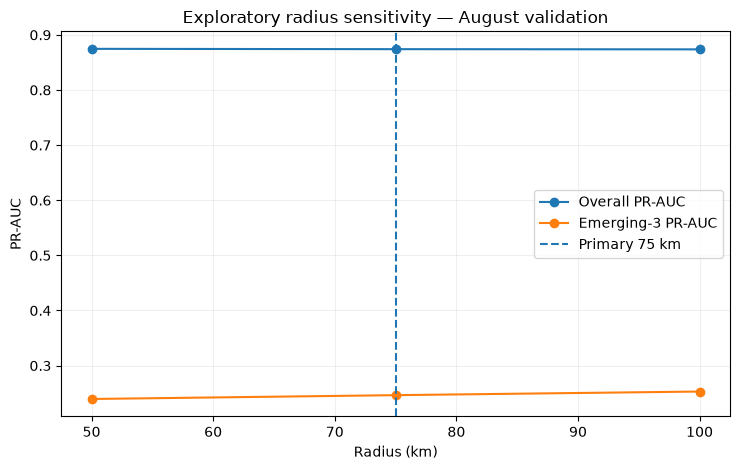

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\figures\01_radius_sensitivity.png


In [19]:
# 18. Radius sensitivity plot

fig, ax = plt.subplots(
    figsize=(7.5, 4.8)
)

ax.plot(
    radius_sensitivity["Radius km"],
    radius_sensitivity["Overall PR-AUC"],
    marker="o",
    label="Overall PR-AUC",
)

ax.plot(
    radius_sensitivity["Radius km"],
    radius_sensitivity["Emerging-3 PR-AUC"],
    marker="o",
    label="Emerging-3 PR-AUC",
)

ax.axvline(
    PRIMARY_RADIUS_KM,
    linestyle="--",
    label="Primary 75 km",
)

ax.set_xlabel("Radius (km)")
ax.set_ylabel("PR-AUC")
ax.set_title("Exploratory radius sensitivity — August validation")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "01_radius_sensitivity.png"
)

plt.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

# PART E — Calibration check for the cumulative models

Calibration is secondary here because Notebook 19 is primarily a mechanism/ranking
experiment. It remains useful because the final thesis may eventually show probability
maps.

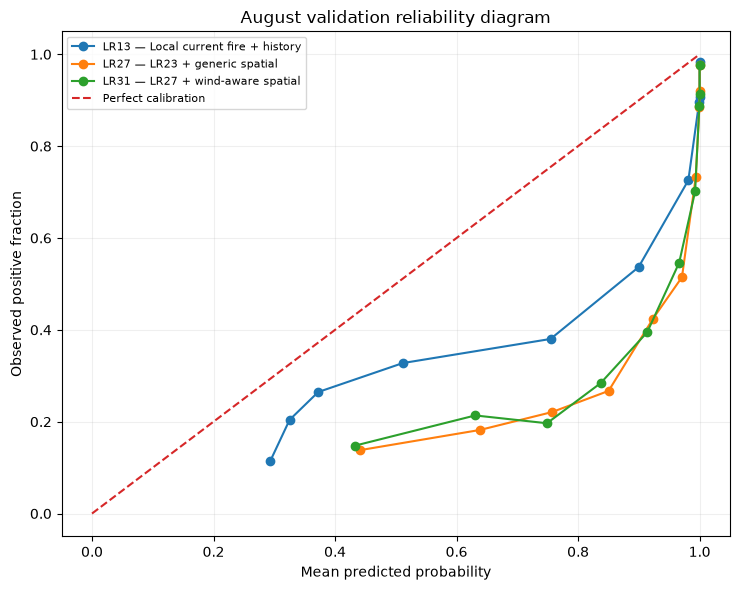

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\figures\02_reliability_spatial_wind.png


In [20]:
# 19. Reliability diagram

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)

for model_name in [
    "LR13 — Local current fire + history",
    "LR27 — LR23 + generic spatial",
    "LR31 — LR27 + wind-aware spatial",
]:
    score = val_scores[model_name]

    prob_true, prob_pred = calibration_curve(
        y_val,
        score,
        n_bins=10,
        strategy="quantile",
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=model_name,
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed positive fraction")
ax.set_title("August validation reliability diagram")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "02_reliability_spatial_wind.png"
)

plt.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

# PART F — Save development-stage artifacts

Only May–August spatial features and August validation outputs are saved here.
September remains sealed and is not evaluated in Notebook 19.

In [21]:
# 20. Save graph, feature table, and validation result tables

edges_path = (
    EXPORT_DIR
    / "edges_primary_75km.csv"
)

dev_features_path = (
    EXPORT_DIR
    / "regional_spatial_wind_features_through_august.csv"
)

overall_path = (
    EXPORT_DIR
    / "overall_validation_results.csv"
)

subgroup_path = (
    EXPORT_DIR
    / "subgroup_validation_results.csv"
)

radius_path = (
    EXPORT_DIR
    / "radius_sensitivity.csv"
)

edges_75.to_csv(
    edges_path,
    index=False,
)

dev_spatial.to_csv(
    dev_features_path,
    index=False,
)

overall_results.to_csv(
    overall_path,
    index=False,
)

subgroup_results.to_csv(
    subgroup_path,
    index=False,
)

radius_sensitivity.to_csv(
    radius_path,
    index=False,
)

print("Saved:")
for p in [
    edges_path,
    dev_features_path,
    overall_path,
    subgroup_path,
    radius_path,
]:
    print("-", p)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\edges_primary_75km.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\regional_spatial_wind_features_through_august.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\overall_validation_results.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\subgroup_validation_results.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\radius_sensitivity.csv


In [22]:
# 21. Save methodology metadata

nb19_metadata = {
    "locked_region_id": LOCKED_REGION_ID,
    "nodes": int(N_NODES),
    "primary_radius_km": float(PRIMARY_RADIUS_KM),
    "sensitivity_radii_km": [
        float(x)
        for x in SENSITIVITY_RADII_KM
    ],
    "edge_direction": "source neighbor -> target node",
    "timing": {
        "local_fire": "day t",
        "neighbor_fire": "day t",
        "weather_wind": "day t",
        "target": "day t+1",
    },
    "generic_spatial_features": GENERIC_SPATIAL,
    "wind_spatial_features": WIND_SPATIAL,
    "wind_interpretation": (
        "source-day wind vector aligned with source-to-target edge; "
        "associative transport-aware exposure, not causal fire spread"
    ),
    "validation_period": [
        "2026-08-01",
        "2026-08-31",
    ],
    "september_evaluated": False,
}

metadata_path = (
    EXPORT_DIR
    / "nb19_methodology_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        nb19_metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved:", metadata_path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind\t2\exports\nb19_methodology_metadata.json


In [23]:
# 22. Final automatic summary

overall_lookup = (
    overall_results
    .set_index("Model")
)

emerging_table = (
    subgroup_results[
        subgroup_results["Context"].eq(
            "Emerging-3 eligible"
        )
    ]
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
)

print("=== Notebook 19 — Spatial + Wind Summary ===")
print()
print("DOMAIN")
print("Region                  :", LOCKED_REGION_ID)
print("Nodes                   :", N_NODES)
print("Primary radius          :", PRIMARY_RADIUS_KM, "km")
print("Directed edges          :", len(edges_75))
print("September               : SEALED")
print()

print("OVERALL AUGUST")
display(
    overall_results[
        [
            "Model",
            "Features",
            "PR-AUC",
            "ROC-AUC",
            "Precision",
            "Recall",
            "F1",
            "Brier",
        ]
    ]
)

print("MECHANISM DELTAS — OVERALL")
display(mechanism_deltas)

print("EMERGING-3 ELIGIBLE")
display(
    emerging_table[
        [
            "Model",
            "Rows",
            "Positives",
            "Prevalence",
            "PR-AUC",
            "Recall@0.5",
            "Precision@0.5",
        ]
    ]
)

print("MECHANISM DELTAS — EMERGING-3")
display(emerging_deltas)

print("RADIUS SENSITIVITY")
display(radius_sensitivity)

print()
print(
    "Interpretation rule: proceed to graph models only after checking whether "
    "generic spatial and/or wind-aware features add stable August information."
)

=== Notebook 19 — Spatial + Wind Summary ===

DOMAIN
Region                  : T2
Nodes                   : 133
Primary radius          : 75.0 km
Directed edges          : 2152
September               : SEALED

OVERALL AUGUST


,Model,Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Brier
0,LR27 — LR23 + generic spatial,27,0.877588,0.853682,0.555094,0.984786,0.709988,0.300253
1,LR13 — Local current fire + history,13,0.877455,0.858476,0.707635,0.875980,0.782859,0.196675
2,LR23 — LR13 + same-cell weather,23,0.876138,0.849698,0.574287,0.965883,0.720303,0.261741
3,LR31 — LR27 + wind-aware spatial,31,0.874095,0.848382,0.556949,0.982941,0.711022,0.297443


MECHANISM DELTAS — OVERALL


,Question,From,To,Delta PR-AUC
0,Same-cell weather beyond local fire/history,LR13,LR23,-0.001317
1,Generic spatial beyond local + weather,LR23,LR27,0.001450
2,Wind alignment beyond generic spatial,LR27,LR31,-0.003493


EMERGING-3 ELIGIBLE


,Model,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
0,LR13 — Local current fire + history,1241,224,0.1805,0.277072,0.147321,0.370787
4,LR27 — LR23 + generic spatial,1241,224,0.1805,0.259863,0.892857,0.198020
6,LR31 — LR27 + wind-aware spatial,1241,224,0.1805,0.246402,0.888393,0.201417
2,LR23 — LR13 + same-cell weather,1241,224,0.1805,0.229095,0.750000,0.201439


MECHANISM DELTAS — EMERGING-3


,Question,Delta Emerging PR-AUC
0,Same-cell weather beyond local fire/history,-0.047977
1,Generic spatial beyond local + weather,0.030769
2,Wind alignment beyond generic spatial,-0.013462


RADIUS SENSITIVITY


,Radius km,Directed edges,Mean degree,Overall PR-AUC,Emerging-3 PR-AUC,Emerging rows,Emerging positives,Primary radius
0,50.0,922,6.932331,0.874687,0.239467,1241,224,False
1,75.0,2152,16.180451,0.874095,0.246402,1241,224,True
2,100.0,3612,27.157895,0.873747,0.252993,1241,224,False



Interpretation rule: proceed to graph models only after checking whether generic spatial and/or wind-aware features add stable August information.


# What to send for review

After running Notebook 19, send:

1. **Section 6** — 75 km graph audit
2. **Section 12** — overall model table
3. **Section 13** — overall mechanism deltas
4. **Section 14** — Emerging/Persistent subgroup table
5. **Section 15** — Emerging mechanism deltas
6. **Section 17** — radius sensitivity
7. **Section 22** — final summary

Do **not** inspect September yet.